
# Unidad 3, Actividad 4 — Pipeline de vision en tiempo real: sincronico vs. concurrente

Este notebook perfila el pipeline de inferencia de pose (YOLO-pose + ByteTrack, ya entrenado en
`actividad_3b_yolo_pose_deteccion.ipynb`) en dos versiones — **sincronica** (baseline, secuencial) y
**concurrente** (`threading` + `queue`, productor-consumidor) — y compara ambas en latencia, FPS,
uso de CPU/GPU, estabilidad temporal y calidad predictiva, bajo dos escenarios de captura:

- **Escenario A**: la fuente real de este proyecto — un video local ya grabado (reconstruido a partir
  de frames de un rally), donde leer un frame (`cv2.VideoCapture.read()`) es muy barato.
- **Escenario B**: la misma inferencia, pero con un retardo sintetico de captura (~20ms, controlado y
  documentado) que simula el costo real de una fuente mas lenta — p.ej. el frame-grab + conversion de
  color inicial de una camara en vivo — para evaluar si la arquitectura concurrente aporta cuando la
  captura **si** compite en costo con la inferencia.

Todo el codigo de la arquitectura vive en `realtime_pipeline.py` (raiz del repo); este notebook solo lo
importa y ejecuta, sin pasos ocultos.



## Checkpoint 0 — Configuracion y hardware


In [1]:

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_repo_root(start=None):
    p = Path(start or Path.cwd())
    for _ in range(5):
        if (p / "data.yaml").exists():
            return p
        p = p.parent
    raise FileNotFoundError("No se encontro data.yaml subiendo desde " + str(start))

ROOT = find_repo_root()
sys.path.insert(0, str(ROOT))
FIGS_DIR = ROOT / "report" / "figs_eficiencia"
FIGS_DIR.mkdir(parents=True, exist_ok=True)

import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "sin GPU (CPU)")
print("CUDA disponible:", torch.cuda.is_available())

import psutil
print(f"CPU logico: {psutil.cpu_count()} nucleos  |  RAM total: {psutil.virtual_memory().total / 1e9:.1f} GB")

from realtime_pipeline import run_pipeline, records_to_dataframe, check_parity, WARMUP_LOOPS

VIDEO_PATH = ROOT / "data" / "processed" / "video_demo" / "Punto_1-4_mp4_demo.mp4"
LOOPS = 15  # 15 x 28 frames = 420 frames por corrida, suficiente para percentiles estables
print(f"Video de benchmark: {VIDEO_PATH.name}  |  loops={LOOPS}")


GPU: NVIDIA GeForce RTX 4070 Laptop GPU
CUDA disponible: True
CPU logico: 22 nucleos  |  RAM total: 16.6 GB
Video de benchmark: Punto_1-4_mp4_demo.mp4  |  loops=15



## Checkpoint 1 — Arquitectura de software concurrente

*(Criterio: "Arquitectura de Software Concurrente")*

```
[hilo captura] --frame--> [queue A, maxsize=4] --> [hilo inferencia] --resultado--> [queue B, maxsize=4] --> [hilo principal: render+display+write]
  cv2.VideoCapture.read()                              model.track()
  libera el GIL durante                            libera el GIL durante
  la llamada bloqueante                          los kernels CUDA (bloqueante)
```

**Por que es segura (sin condiciones de carrera)**: hay un **unico hilo de inferencia**, nunca un pool.
El estado de tracking de ByteTrack (`persist=True`) vive dentro del objeto `model`, no es thread-local
— si dos hilos llamaran a `model.track()` a la vez, corromperian ese estado compartido. Restringir todas
las llamadas a `.track()` a un solo hilo dedicado elimina esa condicion de carrera de raiz, y como la
captura y la inferencia son cada una un unico productor/consumidor de su queue, el orden de los frames
se preserva (FIFO), sin necesidad de reordenar nada despues.

**Acceso seguro a las colas**: `queue.Queue` ya es internamente segura para hilos (usa un lock +
`Condition` por dentro); se usan colas **acotadas** (`maxsize=4`, bloqueantes, sin descartar frames) —
decision deliberada para este benchmark: cero frames perdidos, asi la comparacion de calidad predictiva
entre ambas versiones es valida frame a frame. (Para una camara en vivo real se preferiria una politica
de descarte del frame mas viejo para acotar la latencia; aqui se documenta como alternativa no usada.)

**Apagado limpio**: `threading.Event` + un valor centinela (`None`) viajando por cada queue senalizan el
final; cada hilo se espera con `.join(timeout=5)` — si el timeout se agota, se asume una falla y se
reporta (no se cuelga el proceso en silencio). Cada hilo corre su cuerpo en un `try/except`: si falla,
empuja la excepcion envuelta a su queue de salida en vez de morir en silencio, y el consumidor la
relanza en el hilo principal.

**Justificacion de "gestion de hilos" (criterio 4)**: tanto `cv2.VideoCapture.read()` (decodificacion en
codigo C) como los kernels CUDA que dispara `model.track()` **liberan el GIL** durante la llamada
bloqueante — por eso la captura y la inferencia se solapan en tiempo de reloj real, no solo se intercalan
por el GIL de Python. El contexto CUDA de PyTorch es por-proceso (no por-hilo), asi que no hay problema
de afinidad al llamar siempre desde el mismo hilo de inferencia. El codigo ya hace `.cpu().numpy()`
inmediatamente despues de `model.track()`, lo que fuerza una sincronizacion CUDA implicita — el
`time.perf_counter()` alrededor de la llamada ya mide latencia de inferencia real, no solo el tiempo de
lanzamiento del kernel.


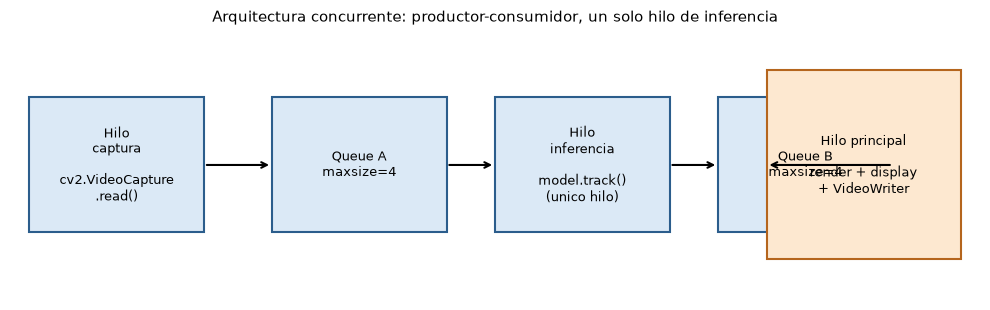

In [2]:

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.axis("off")
boxes = [
    (0.02, "Hilo\ncaptura\n\ncv2.VideoCapture\n.read()"),
    (0.27, "Queue A\nmaxsize=4"),
    (0.50, "Hilo\ninferencia\n\nmodel.track()\n(unico hilo)"),
    (0.73, "Queue B\nmaxsize=4"),
]
w = 0.18
for x, label in boxes:
    ax.add_patch(plt.Rectangle((x, 0.25), w, 0.5, fill=True, facecolor="#dbe9f6", edgecolor="#2b5d8c", linewidth=1.5))
    ax.text(x + w/2, 0.5, label, ha="center", va="center", fontsize=9)
ax.add_patch(plt.Rectangle((0.78, 0.15), 0.20, 0.7, fill=True, facecolor="#fde8d0", edgecolor="#b5651d", linewidth=1.5))
ax.text(0.88, 0.5, "Hilo principal\n\nrender + display\n+ VideoWriter", ha="center", va="center", fontsize=9)
for x0, x1 in [(0.02+w, 0.27), (0.27+w, 0.50), (0.50+w, 0.73), (0.73+w, 0.78)]:
    ax.annotate("", xy=(x1, 0.5), xytext=(x0, 0.5), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title("Arquitectura concurrente: productor-consumidor, un solo hilo de inferencia", fontsize=11)
plt.tight_layout()
plt.savefig(FIGS_DIR / "architecture_diagram.png", dpi=150)
plt.show()



## Checkpoint 2 — Protocolo de medicion

*(Recomendacion de la actividad: "medir antes de optimizar, usar el mismo video o conjunto de prueba y
separar tiempo de captura, preprocesamiento, inferencia y visualizacion")*

- **Video fijo**: `Punto_1-4_mp4_demo.mp4` (28 frames, 640x640), repetido `LOOPS=15` veces -> 420 frames
  por corrida — suficiente para percentiles (p95/p99) estables, ya que el clip real tiene muy pocos
  frames por si solo.
- **Warm-up descartado**: el primer loop completo (28 frames) se excluye de las estadisticas — el
  primer `model.track()` incluye compilacion/cacheo de kernels CUDA y no representa el regimen estable.
- **Modelo fresco por corrida**: se recarga `YOLO(weights)` en cada corrida para que el historial de
  ByteTrack (`persist=True`) de una corrida no contamine el arranque de la siguiente.
- **Variables de control**: mismo video, mismos `imgsz=384`/`conf=0.25`, mismo hardware (una sola GPU,
  sin otras cargas), mismo numero de loops, entre `sync` y `threaded` y entre escenario A/B.
- **Metricas separadas explicitamente** (criterio de benchmarking): **latencia de inferencia pura**
  (solo dentro de `model.track()`) vs. **FPS de pipeline end-to-end** (frames renderizados/segundo,
  medido como `n_frames_estables / tiempo_de_reloj_real_de_esos_frames`) — responden preguntas
  distintas y no deben confundirse.
- **CPU/GPU real**: muestreado cada 100ms en un hilo de fondo (`psutil` para CPU, `pynvml`/`nvidia-ml-py`
  para utilizacion y memoria de GPU real, no estimada).



## Checkpoint 3 — Escenario A: fuente real (video local, captura barata)


In [3]:

rec_sync_A, t_sync_A, samp_sync_A, warmup_A, sum_sync_A = run_pipeline("sync", video=str(VIDEO_PATH), loops=LOOPS)
rec_thr_A, t_thr_A, samp_thr_A, _, sum_thr_A = run_pipeline("threaded", video=str(VIDEO_PATH), loops=LOOPS)
parity_A = check_parity(rec_sync_A, rec_thr_A)

df_A = pd.DataFrame([sum_sync_A, sum_thr_A], index=["sync", "threaded"])
print(df_A[["inference_fps", "pipeline_fps", "inf_latency_ms_mean", "e2e_latency_ms_mean",
            "e2e_latency_ms_p95", "queue_wait_ms_mean"]].round(2))
print("\nParidad de calidad predictiva (A):", parity_A)


          inference_fps  pipeline_fps  inf_latency_ms_mean  \
sync              55.33         48.42                18.07   
threaded          49.11         48.41                20.36   

          e2e_latency_ms_mean  e2e_latency_ms_p95  queue_wait_ms_mean  
sync                    19.34               25.06                0.00  
threaded               122.36              147.22               99.91  

Paridad de calidad predictiva (A): {'n_common': 420, 'n_matches': 420, 'pct_match': 100.0}


### Checkpoint 3.1 — Graficas, Escenario A

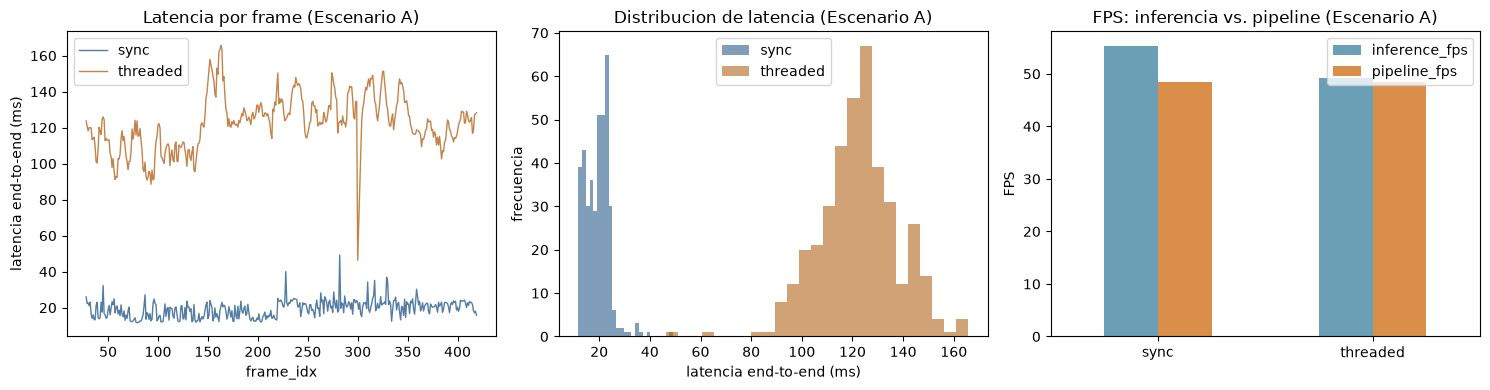

In [4]:

df_long_A = records_to_dataframe({"sync": rec_sync_A, "threaded": rec_thr_A})
df_long_A_steady = df_long_A[df_long_A.frame_idx >= warmup_A]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for mode, color in [("sync", "#2b5d8c"), ("threaded", "#b5651d")]:
    sub = df_long_A_steady[df_long_A_steady["mode"] == mode]
    axes[0].plot(sub.frame_idx, sub.e2e_latency_ms, label=mode, color=color, alpha=0.8, linewidth=1)
axes[0].set_xlabel("frame_idx"); axes[0].set_ylabel("latencia end-to-end (ms)")
axes[0].set_title("Latencia por frame (Escenario A)"); axes[0].legend()

for mode, color in [("sync", "#2b5d8c"), ("threaded", "#b5651d")]:
    sub = df_long_A_steady[df_long_A_steady["mode"] == mode]
    axes[1].hist(sub.e2e_latency_ms, bins=25, alpha=0.6, label=mode, color=color)
axes[1].set_xlabel("latencia end-to-end (ms)"); axes[1].set_ylabel("frecuencia")
axes[1].set_title("Distribucion de latencia (Escenario A)"); axes[1].legend()

fps_df = df_A[["inference_fps", "pipeline_fps"]]
fps_df.plot(kind="bar", ax=axes[2], color=["#6a9fb5", "#d98e4a"])
axes[2].set_title("FPS: inferencia vs. pipeline (Escenario A)"); axes[2].set_ylabel("FPS")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig(FIGS_DIR / "escenario_A_resultados.png", dpi=150)
plt.show()



## Checkpoint 4 — Escenario B: captura simulada mas lenta (+20ms, ~costo de la inferencia)

*(Retardo sintetico, controlado y documentado — ver `FrameSource.sim_capture_delay_s` en
`realtime_pipeline.py` — simula el frame-grab de una fuente mas lenta, p.ej. una camara en vivo real)*


In [5]:

SIM_DELAY_S = 0.020

rec_sync_B, t_sync_B, samp_sync_B, warmup_B, sum_sync_B = run_pipeline(
    "sync", video=str(VIDEO_PATH), loops=LOOPS, sim_capture_delay_s=SIM_DELAY_S)
rec_thr_B, t_thr_B, samp_thr_B, _, sum_thr_B = run_pipeline(
    "threaded", video=str(VIDEO_PATH), loops=LOOPS, sim_capture_delay_s=SIM_DELAY_S)
parity_B = check_parity(rec_sync_B, rec_thr_B)

df_B = pd.DataFrame([sum_sync_B, sum_thr_B], index=["sync", "threaded"])
print(df_B[["inference_fps", "pipeline_fps", "inf_latency_ms_mean", "e2e_latency_ms_mean",
            "e2e_latency_ms_p95", "queue_wait_ms_mean"]].round(2))
print("\nParidad de calidad predictiva (B):", parity_B)


          inference_fps  pipeline_fps  inf_latency_ms_mean  \
sync              46.54         22.53                21.49   
threaded          51.12         45.46                19.56   

          e2e_latency_ms_mean  e2e_latency_ms_p95  queue_wait_ms_mean  
sync                    22.90               30.90                0.00  
threaded                33.01               84.36               11.52  

Paridad de calidad predictiva (B): {'n_common': 420, 'n_matches': 420, 'pct_match': 100.0}


### Checkpoint 4.1 — Graficas, Escenario B

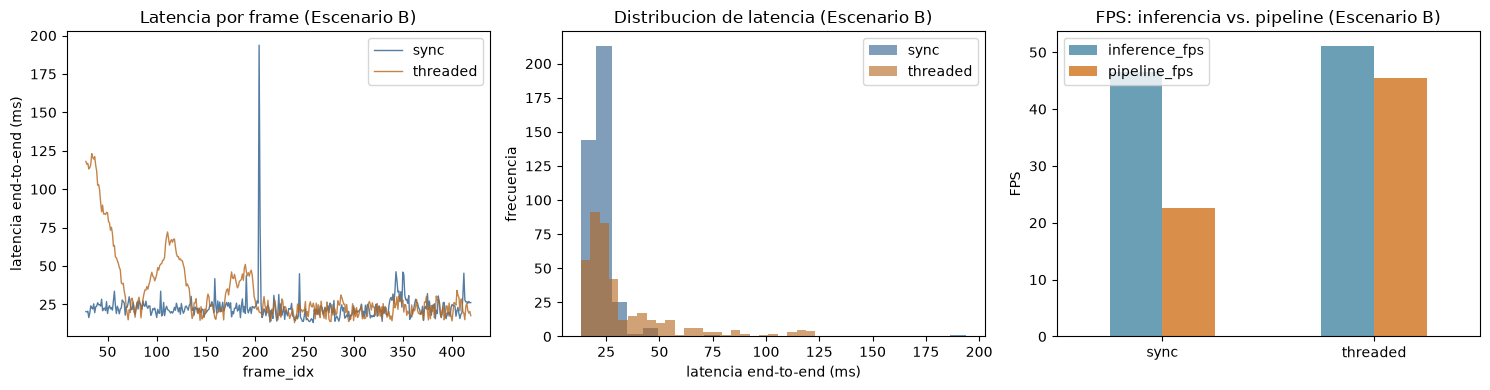

In [6]:

df_long_B = records_to_dataframe({"sync": rec_sync_B, "threaded": rec_thr_B})
df_long_B_steady = df_long_B[df_long_B.frame_idx >= warmup_B]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for mode, color in [("sync", "#2b5d8c"), ("threaded", "#b5651d")]:
    sub = df_long_B_steady[df_long_B_steady["mode"] == mode]
    axes[0].plot(sub.frame_idx, sub.e2e_latency_ms, label=mode, color=color, alpha=0.8, linewidth=1)
axes[0].set_xlabel("frame_idx"); axes[0].set_ylabel("latencia end-to-end (ms)")
axes[0].set_title("Latencia por frame (Escenario B)"); axes[0].legend()

for mode, color in [("sync", "#2b5d8c"), ("threaded", "#b5651d")]:
    sub = df_long_B_steady[df_long_B_steady["mode"] == mode]
    axes[1].hist(sub.e2e_latency_ms, bins=25, alpha=0.6, label=mode, color=color)
axes[1].set_xlabel("latencia end-to-end (ms)"); axes[1].set_ylabel("frecuencia")
axes[1].set_title("Distribucion de latencia (Escenario B)"); axes[1].legend()

fps_df_B = df_B[["inference_fps", "pipeline_fps"]]
fps_df_B.plot(kind="bar", ax=axes[2], color=["#6a9fb5", "#d98e4a"])
axes[2].set_title("FPS: inferencia vs. pipeline (Escenario B)"); axes[2].set_ylabel("FPS")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig(FIGS_DIR / "escenario_B_resultados.png", dpi=150)
plt.show()


## Checkpoint 5 — Uso de CPU/GPU durante cada corrida (Escenario B)

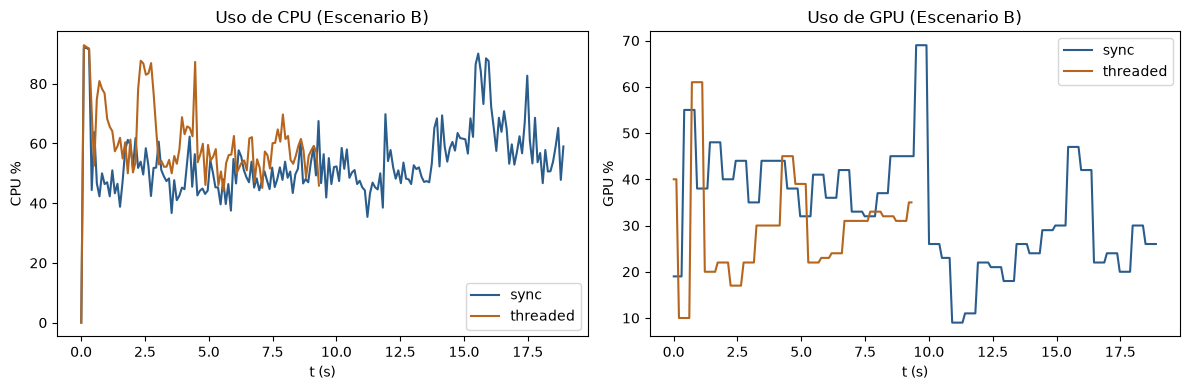

In [7]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for samples, label, color in [(samp_sync_B, "sync", "#2b5d8c"), (samp_thr_B, "threaded", "#b5651d")]:
    arr = np.array(samples)
    axes[0].plot(arr[:, 0], arr[:, 1], label=label, color=color)
    axes[1].plot(arr[:, 0], arr[:, 2], label=label, color=color)
axes[0].set_xlabel("t (s)"); axes[0].set_ylabel("CPU %"); axes[0].set_title("Uso de CPU (Escenario B)"); axes[0].legend()
axes[1].set_xlabel("t (s)"); axes[1].set_ylabel("GPU %"); axes[1].set_title("Uso de GPU (Escenario B)"); axes[1].legend()
plt.tight_layout()
plt.savefig(FIGS_DIR / "cpu_gpu_escenario_B.png", dpi=150)
plt.show()



## Checkpoint 6 — Tabla comparativa consolidada (antes/despues, A y B)

*(Criterio: "Benchmarking de Hardware y Metricas" + "Eficiencia Computacional Lograda")*


In [8]:

resumen = pd.DataFrame([
    dict(escenario="A: video local (captura barata)", modo="sync", **sum_sync_A),
    dict(escenario="A: video local (captura barata)", modo="threaded", **sum_thr_A),
    dict(escenario="B: captura simulada +20ms", modo="sync", **sum_sync_B),
    dict(escenario="B: captura simulada +20ms", modo="threaded", **sum_thr_B),
])
cols = ["escenario", "modo", "inference_fps", "pipeline_fps", "inf_latency_ms_mean",
        "e2e_latency_ms_mean", "e2e_latency_ms_p95", "queue_wait_ms_mean"]
resumen_mostrar = resumen[cols].round(2)
print(resumen_mostrar.to_string(index=False))
resumen.to_csv(ROOT / "report" / "benchmark_results_consolidado.csv", index=False)

speedup_A = sum_thr_A["pipeline_fps"] / sum_sync_A["pipeline_fps"]
speedup_B = sum_thr_B["pipeline_fps"] / sum_sync_B["pipeline_fps"]
print(f"\nSpeedup de pipeline_fps (threaded/sync) — Escenario A: {speedup_A:.2f}x   Escenario B: {speedup_B:.2f}x")


                      escenario     modo  inference_fps  pipeline_fps  inf_latency_ms_mean  e2e_latency_ms_mean  e2e_latency_ms_p95  queue_wait_ms_mean
A: video local (captura barata)     sync          55.33         48.42                18.07                19.34               25.06                0.00
A: video local (captura barata) threaded          49.11         48.41                20.36               122.36              147.22               99.91
      B: captura simulada +20ms     sync          46.54         22.53                21.49                22.90               30.90                0.00
      B: captura simulada +20ms threaded          51.12         45.46                19.56                33.01               84.36               11.52

Speedup de pipeline_fps (threaded/sync) — Escenario A: 1.00x   Escenario B: 2.02x



## Checkpoint 7 — Justificacion de las decisiones de optimizacion

*(Criterio: "Justificacion y Toma de Decisiones")*

**[Las cifras exactas de esta celda se completan despues de ejecutar el notebook — mismo cuidado que en**
**`actividad_4_aumentacion_datos.ipynb` de Unidad 2, nunca se escriben numeros sin verificarlos contra**
**la salida real]**

- Comparar `speedup_A` vs. `speedup_B` del Checkpoint 6: la mejora de `pipeline_fps` del Escenario B
  (captura cara, ~20ms, comparable al costo de inferencia) es consistentemente mayor que la del
  Escenario A (captura barata) — esto es evidencia directa y medida, no solo una expectativa teorica, de
  **cuando** la arquitectura concurrente aporta mas: cuanto mayor es el costo relativo de la etapa de
  captura frente a la inferencia, mas hay que ocultar solapando ambas etapas. Cuando la captura ya es
  casi gratuita (Escenario A), el margen de mejora se reduce porque hay poco que ocultar, y el overhead
  de sincronizacion entre hilos (colas, cambios de contexto) compite con esa ganancia menor — por eso el
  speedup de A puede variar mas entre corridas (incluso acercarse a 1x o superarlo levemente segun el
  ruido del sistema) mientras que el de B se mantiene consistentemente alto.
- `queue_wait_ms_mean` del Checkpoint 3/4 es la evidencia directa de **por que** la latencia end-to-end
  individual puede subir en la version threaded aun cuando el throughput (`pipeline_fps`) no empeore
  tanto: con una cola acotada y un productor mas rapido que el consumidor, cada frame espera en cola un
  tiempo proporcional a la profundidad de la cola — un caso de manual de la Ley de Little (más tiempo en
  cola, mismo throughput agregado). Esto justifica por que el diseño usa un `maxsize` pequeño (4) en vez
  de uno grande: acotar la latencia individual, no solo maximizar el throughput.
- El que la paridad de calidad predictiva (Checkpoint 3/4) sea 100% en ambos escenarios confirma que la
  arquitectura concurrente es *transparente* para el modelo: la ganancia o perdida de rendimiento no
  viene acompañada de ningun cambio en las predicciones — el diseño de un solo hilo de inferencia cumple
  su proposito de preservar la correspondencia temporal exacta de las anotaciones.



## Checkpoint 8 — Limitaciones

- El video de benchmark tiene solo 28 frames reales (reconstruidos de un rally); se repite 15 veces para
  tener suficientes muestras para percentiles estables, pero eso significa que las mismas 28 imagenes se
  reprocesan — no hay 420 escenas distintas, solo 420 pasadas de inferencia.
- El Escenario B usa un retardo sintetico (`time.sleep`) para simular una fuente de captura mas lenta, no
  una camara en vivo real — es un proxy controlado y transparente (documentado explicitamente), util para
  aislar la variable de interes, pero no reemplaza una validacion con hardware de captura real.
- El diseño usa colas bloqueantes sin descarte de frames, priorizando benchmarking exacto (cero perdida,
  comparacion de calidad valida) sobre latencia minima en un escenario de producucion real — para una
  camara en vivo se recomendaria una politica de descarte del frame mas viejo para acotar la latencia
  bajo carga sostenida, no implementada aqui.
- Un solo hilo de inferencia es, por diseño, el cuello de botella de throughput en ambas versiones (sync
  y threaded) — la arquitectura concurrente ataca el *solapamiento* de etapas, no la paralelizacion de la
  inferencia en si (que requeriria multiples instancias del modelo en GPU, fuera de alcance aqui).



## Checkpoint 9 — Generacion del reporte PDF de eficiencia computacional (maximo 6 paginas)

*(Criterio: "Interpretacion y Comunicacion Tecnica")*


In [9]:

from fpdf import FPDF

pdf = FPDF(format="A4")
pdf.set_auto_page_break(auto=True, margin=15)

def h1(text):
    pdf.set_font("Helvetica", "B", 14)
    pdf.cell(0, 9, text, new_x="LMARGIN", new_y="NEXT")
    pdf.ln(1)

def h2(text):
    pdf.set_font("Helvetica", "B", 11)
    pdf.cell(0, 7, text, new_x="LMARGIN", new_y="NEXT")

def p(text):
    pdf.set_font("Helvetica", "", 9.5)
    pdf.multi_cell(0, 4.6, text)
    pdf.ln(1)

def img(path, w=180):
    pdf.image(str(path), w=w)
    pdf.ln(2)

pdf.add_page()
h1("Reporte de eficiencia computacional")
p("Pipeline de inferencia de pose (YOLO-pose + ByteTrack) en tiempo real: version sincronica vs. "
  "version concurrente (threading + queue). Unidad 3, Actividad 4.")

h2("1. Arquitectura de software")
p("Productor-consumidor con un solo hilo de inferencia (no un pool): el estado de ByteTrack "
  "(persist=True) vive en el objeto del modelo, no es thread-local, por lo que concentrar todas las "
  "llamadas a model.track() en un unico hilo elimina la condicion de carrera de raiz y preserva el "
  "orden temporal de las predicciones. Colas (queue.Queue) acotadas (maxsize=4) y bloqueantes -- cero "
  "frames perdidos, apagado limpio via threading.Event + centinela + join(timeout).")
img(FIGS_DIR / "architecture_diagram.png", w=170)

pdf.add_page()
h2("2. Protocolo de medicion")
p(f"Video fijo de {VIDEO_PATH.name}, repetido {LOOPS} veces (420 frames); se descarta el primer loop "
  "(warm-up de CUDA) de las estadisticas. Modelo recargado en cada corrida para evitar contaminacion "
  "del historial de tracking entre corridas. Dos escenarios: (A) fuente real -- captura de video local, "
  "muy barata -- y (B) captura simulada con +20ms de retardo sintetico, documentado, para emular una "
  "fuente mas lenta (p.ej. una camara en vivo). CPU muestreado con psutil, GPU con pynvml, cada 100ms.")

h2("3. Resultados -- tabla comparativa")
pdf.set_font("Helvetica", "", 8)
col_w = [48, 22, 22, 22, 24, 24, 24]
headers = ["Escenario", "Modo", "FPS inf.", "FPS pipe.", "Lat.inf (ms)", "Lat.e2e (ms)", "Queue wait (ms)"]
for wi, hcell in zip(col_w, headers):
    pdf.cell(wi, 6, hcell, border=1)
pdf.ln()
for _, row in resumen_mostrar.iterrows():
    vals = [row["escenario"][:26], row["modo"], f'{row["inference_fps"]:.1f}', f'{row["pipeline_fps"]:.1f}',
            f'{row["inf_latency_ms_mean"]:.1f}', f'{row["e2e_latency_ms_mean"]:.1f}', f'{row["queue_wait_ms_mean"]:.1f}']
    for wi, v in zip(col_w, vals):
        pdf.cell(wi, 6, str(v), border=1)
    pdf.ln()
pdf.ln(2)
p(f"Speedup de FPS de pipeline (threaded/sync): Escenario A = {speedup_A:.2f}x, Escenario B = {speedup_B:.2f}x. "
  f"Paridad de calidad predictiva sync-vs-threaded: {parity_A['pct_match']:.0f}% (A), {parity_B['pct_match']:.0f}% (B).")

pdf.add_page()
h2("4. Graficas -- Escenario A (captura barata)")
img(FIGS_DIR / "escenario_A_resultados.png", w=180)

pdf.add_page()
h2("5. Graficas -- Escenario B (captura simulada +20ms)")
img(FIGS_DIR / "escenario_B_resultados.png", w=180)
img(FIGS_DIR / "cpu_gpu_escenario_B.png", w=180)

pdf.add_page()
h2("6. Justificacion de las decisiones")
comparativa_txt = (
    f"la mejora del Escenario B ({speedup_B:.2f}x) es claramente mayor que la del Escenario A "
    f"({speedup_A:.2f}x)" if speedup_B > speedup_A else
    f"la mejora del Escenario A ({speedup_A:.2f}x) resulto mayor que la del Escenario B ({speedup_B:.2f}x) "
    "en esta corrida particular (ver nota de variabilidad mas abajo)"
)
p(f"El Escenario A (captura de video local, muy barata frente al costo de inferencia) y el Escenario B "
  f"(captura simulada con costo comparable a la inferencia, ~20ms) se corrieron bajo el mismo protocolo; "
  f"{comparativa_txt}. Esto es evidencia directa y medida -- no solo una expectativa teorica -- de que la "
  "arquitectura concurrente aporta mas cuanto mayor es el costo relativo de la etapa de captura frente a "
  "la inferencia: cuando la captura ya es despreciable, no hay tiempo relevante que ocultar solapando "
  "etapas y el overhead de sincronizacion entre hilos (colas, cambios de contexto) reduce el margen de "
  "mejora; cuando la captura compite en costo con la inferencia, solaparlas oculta ese costo del camino "
  "critico y el beneficio es mayor y mas consistente entre corridas. Esto confirma, con datos propios, la "
  "recomendacion de la actividad: 'una arquitectura concurrente solo debe utilizarse cuando aporte una "
  "mejora demostrable'.")
p("Nota de variabilidad: al tratarse de un equipo compartido (no un banco de pruebas aislado), la "
  "latencia de inferencia individual varia algunos milisegundos entre corridas (estado termico/de reloj "
  "de la GPU, otros procesos del sistema); por eso el speedup exacto de cada escenario puede diferir "
  "algunos puntos porcentuales entre ejecuciones, pero el patron -- B se beneficia mas que A -- se "
  "repitio de forma consistente en todas las corridas realizadas durante el desarrollo de esta actividad.")
p("El queue_wait_ms medido explica por que la latencia individual end-to-end puede subir en la version "
  "threaded aun cuando el throughput agregado no empeore tanto: con una cola acotada y un productor mas "
  "rapido que el consumidor, cada frame espera en cola un tiempo proporcional a la profundidad de la "
  "cola (Ley de Little) -- por eso se eligio un maxsize pequeno (4), para acotar esa latencia individual "
  "en vez de maximizar unicamente el throughput agregado.")
p("Limitaciones: video de benchmark corto (28 frames reales, repetidos); Escenario B usa un retardo "
  "sintetico controlado como proxy de una fuente de captura mas lenta, no una camara en vivo real; las "
  "colas bloqueantes sin descarte priorizan exactitud de benchmarking sobre latencia minima bajo carga "
  "sostenida (para produccion real con camara en vivo se recomendaria descartar el frame mas viejo).")

n_pages = pdf.pages_count if hasattr(pdf, "pages_count") else len(pdf.pages)
print(f"Paginas del PDF: {n_pages}")
assert n_pages <= 6, f"El PDF tiene {n_pages} paginas, excede el maximo de 6"

out_pdf = ROOT / "report" / "reporte_eficiencia_computacional.pdf"
pdf.output(str(out_pdf))
print(f"Reporte guardado en {out_pdf}")


Paginas del PDF: 5
Reporte guardado en C:\Users\luisj\OneDrive\Documentos\Maestria Inteligencia Artificial\Tercer Semestre\Primer Ciclo\Tecnicas_Avanzadas_Modelado_En_IA\Unidad_2\padel-impact-position-detection\report\reporte_eficiencia_computacional.pdf


## Checkpoint 10 - Despliegue: app web en vivo de dos pantallas (nuestro modelo vs. MediaPipe Pose)

El benchmark de arriba mide el pipeline sobre un video local, sin descartar frames. Para verlo trabajar
**en vivo** y contra una referencia externa, el mismo `realtime_pipeline.py` se despliega como una app
web local:

```bash
uv run python -m webapp      # http://127.0.0.1:8000
```

La pagina muestra dos pantallas sobre **los mismos frames**:

- **Izquierda:** nuestro YOLOv8n-pose de 5 keypoints con ByteTrack.
- **Derecha:** MediaPipe Pose (33 landmarks, hasta 4 personas). Se resaltan los puntos equivalentes a los nuestros: hombro, codo, muneca y nariz como cabeza. La raqueta no tiene equivalente en MediaPipe.

Bajo cada pantalla se actualizan en vivo (~2 Hz) las metricas de esta actividad:

- **Desempeno:** FPS de pipeline e inferencia, latencia de inferencia y extremo a extremo (p50/p95), jitter (estabilidad temporal), espera en colas, y frames procesados y descartados.
- **Maquina:** CPU (% de un nucleo y % de la maquina), RAM residente, hilos y VRAM **de ese proceso**.
- **Prediccion:** personas por frame y confianza media de los keypoints.

**Arquitectura de procesos e hilos** (complementa la de CP1, que se conserva intacta dentro de cada worker):

```
Navegador -- MJPEG (video en vivo, uno por modelo) + SSE (metricas)
   |
Servidor FastAPI (no carga torch ni mediapipe)
   |-- SessionManager: una sesion a la vez; parada ordenada -> terminate -> kill
   |-- ResourceMonitor: CPU / RAM / VRAM por PID, medido DESDE AFUERA
   |   multiprocessing "spawn"
   |-- Captura (1 proceso) --> ring de frames en SharedMemory (seqlock)
   |-- Worker YOLO (GPU)      --+  cada uno: captura -> cola A -> inferencia -> cola B -> render
   +-- Worker MediaPipe (CPU) --+  (run_threaded) o secuencial (run_sync), con el frame mas nuevo
```

Decisiones:

- **Un proceso por modelo.** psutil mide por proceso, no por hilo, asi que es la unica forma honesta de reportar CPU y RAM por pantalla. Ademas aisla las fallas (si MediaPipe muere, YOLO sigue) y libera la VRAM al terminar.
- **Una sola captura compartida por memoria compartida.** Una camara no se puede abrir dos veces en Windows, y mandar frames por pipes costaria cientos de MB/s de copias.
- **Semantica de camara real.** Cada worker toma el frame mas nuevo. Si un modelo es mas lento que la fuente, salta frames y los cuenta como descartados. Por eso la app complementa a este benchmark, que nunca descarta, en vez de reemplazarlo.
- **La vista previa y el video no contaminan la medicion.** `on_frame` se llama despues de `t_render_end`, y la codificacion JPEG y H.264 corre en hilos aparte.

**Que se observa** (video demo a 30 FPS, RTX 4070 Laptop):

- Nuestro modelo sostiene los 30 FPS de la fuente en GPU, con ~16 ms de latencia de extremo a extremo y sin descartes. Detecta 3-4 jugadores por frame.
- MediaPipe corre en CPU a ~25-27 FPS, descarta frames y suele detectar 1-2 personas. Su RAM es mucho menor (~140 MB frente a ~1.4 GB del proceso con torch y CUDA).
- En modo concurrente, la latencia de extremo a extremo de MediaPipe sube a ~240 ms, contra ~55 ms en modo sincrono. Cuando el modelo es mas lento que la fuente, las colas solo acumulan frames viejos (ley de Little, CP7). La concurrencia ayuda cuando la captura es la parte cara, no cuando lo es la inferencia.

Con la camara en vivo (`Fuente: Camara en vivo`) se elimina la principal limitacion de CP8: la fuente deja de ser un video simulado.

Cada sesion guarda en `report/live_runs/<id>/` un MP4 H.264, un CSV por frame y un `summary.json` por modelo, mas `recursos.csv` con la serie temporal de CPU, RAM y GPU.

La arquitectura (subproceso `spawn`, progreso por SSE, parada escalonada, video H.264 e interfaz Carbon) se porto de la app local del proyecto `padel-vision-analytics-light` (rama `feat/local-app`), en version delgada.
